# Decision Tree Model

CRISP-DM phase: Modelling + Evaluation

This notebook trains a decision tree to predict whether a Kenyan county will have a recorded flood next month (`flood_next_month`), using the 24 features prepared in the preprocessing notebook.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score, average_precision_score

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})

### 1.3 Features and Target

In [3]:
#columns that are not features: keys, target and the baseline
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month', 'flood_this_month']

In [4]:
#separating the features (X) from the target (y)
X_train = train.drop(not_features, axis=1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis=1)
y_test = test['flood_next_month']

In [5]:
#shapes and number of floods in each set
print(X_train.shape, y_train.sum())
print(X_test.shape, y_test.sum())

(9870, 24) 882
(2820, 24) 144


#### Observation

The training set has 9,870 rows (July 2002 to December 2019) with 882 floods, and the test set has 2,820 rows (2020 to 2024) with 144 floods. Both have the same 24 features. The 4 keys, the target and the baseline `flood_this_month` are not features.

## 2. Cross-Validation

All choices in this notebook (class weights, tree size, `max_depth`) are made with 5-fold cross-validation on the training set only. The test set is used once, at the end.

The folds keep **whole years together** (`GroupKFold` with the year as the group). The 47 counties in the same month share the same weather: `oni` and `dmi` have the same value for every county, and floods often hit many counties at once. If one county's October 2015 is in the training part and another county's October 2015 is in the validation part, a tree can learn "October 2015 was a flood month" and the scores look better than they really are. With whole years held out, each fold is tested on years the tree has not seen at all, which is closer to predicting the future.

The main measure is **recall for floods**: a missed flood can cost lives, while a false alarm means a county prepares for a flood that does not come. A model that flags almost every month would reach a high recall but waste resources and lose trust, so precision and F1 are always shown next to recall.

**How a setting is chosen:** the setting with the highest mean recall is found first. Every setting whose mean recall is within one standard deviation of it counts as equally good on recall, and among those the one with the highest mean F1 is chosen. If their F1 values are also within one standard deviation, the simplest setting is chosen. If the best setting is at the edge of the range tried, values beyond the edge are tested too.

In [6]:
#5-fold cross-validation that keeps whole years together
year_cv = GroupKFold(n_splits=5)

In [7]:
#years, rows and floods in the validation part of each fold
for fold, (train_idx, val_idx) in enumerate(year_cv.split(X_train, y_train, groups=train['year']), start=1):
    val_rows = train.iloc[val_idx]
    print('fold', fold, 'years', val_rows['year'].unique(), 'rows', len(val_rows), 'floods', val_rows['flood_next_month'].sum(), 'flood rate', round(val_rows['flood_next_month'].mean(), 3))

fold 1 years [2004 2009 2014 2019] rows 2256 floods 128 flood rate 0.057
fold 2 years [2003 2008 2013 2018] rows 2256 floods 175 flood rate 0.078
fold 3 years [2002 2007 2012 2017] rows 1974 floods 211 flood rate 0.107
fold 4 years [2006 2011 2016] rows 1692 floods 174 flood rate 0.103
fold 5 years [2005 2010 2015] rows 1692 floods 194 flood rate 0.115


#### Observation

Each fold holds out whole years: three or four years spread across the period (for example 2004, 2009, 2014 and 2019), so every fold has early, middle and late years. Folds 1 and 2 have 2,256 rows (4 full years of 564 rows), folds 4 and 5 have 1,692 rows (3 full years), and fold 3 has 1,974 rows because it also holds 2002, which only has 6 months. Together the folds cover all 9,870 rows and all 882 floods once. The flood rate changes from 5.7% in fold 1 (128 floods), which holds quiet years such as 2014 and 2019, to 11.5% in fold 5 (194 floods), which holds 2015, the heaviest flood year. Because the folds are not balanced on floods, the scores are expected to change noticeably from fold to fold, especially precision.

## 3. Base Model

The decision tree is first trained with all default settings: no limit on depth, no class weights. It is judged with the year-based folds from Section 2.

In [8]:
#base model with all default settings
model_default = DecisionTreeClassifier(random_state=42)

In [9]:
#cross-validation predictions for the default model
y_pred_default = cross_val_predict(model_default, X_train, y_train, cv=year_cv, groups=train['year'])
print(classification_report(y_train, y_pred_default, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.92      0.90      0.91      8988
     1 flood       0.15      0.19      0.17       882

    accuracy                           0.84      9870
   macro avg       0.54      0.54      0.54      9870
weighted avg       0.85      0.84      0.84      9870



In [10]:
#number of floods found, missed and false alarms for the default model
print(confusion_matrix(y_train, y_pred_default))

[[8087  901]
 [ 718  164]]


In [11]:
#recall, precision and f1 in each fold for the default model
scores_default = cross_validate(model_default, X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_default['test_recall'].round(3))
print(scores_default['test_recall'].mean().round(3), scores_default['test_recall'].std().round(3))
print(scores_default['test_precision'].mean().round(3), scores_default['test_f1'].mean().round(3))

[0.211 0.16  0.142 0.195 0.232]
0.188 0.033
0.158 0.168


#### Observation

With all default settings the tree finds only 164 of the 882 floods (recall 0.19) and misses 718. It raises 1,065 flood warnings, but only 164 of them are real floods (precision 0.15), so 901 no-flood months get a false alarm. Flood F1 is 0.17. The tree gives more warnings than there are floods, yet most of them land on the wrong months, which suggests it learned very specific rules from the training years that do not carry over to the years it has not seen. Its accuracy is 84%, which is lower than always saying "no flood" (91%), so accuracy is not a useful guide here.

The recall changes between the folds from 0.142 (fold 3) to 0.232 (fold 5, which holds the heavy flood year 2015), with a mean of 0.188 and a standard deviation of 0.033. The mean precision is 0.158 and the mean F1 is 0.168. The default tree is a weak starting point for finding floods; the next two sections look at the class imbalance and at the size of the tree.

## 4. Class Weights

Only a small share of the training months are followed by a flood, so the tree can look good by predicting "no flood" almost everywhere. With `class_weight='balanced'`, each flood row counts more than each no-flood row, so missing floods costs the tree more while it learns.

In [12]:
#share of each class in the training set
y_train.value_counts(normalize=True).round(3)

flood_next_month
0    0.911
1    0.089
Name: proportion, dtype: float64

In [13]:
#default tree with balanced class weights
model_balanced = DecisionTreeClassifier(class_weight='balanced', random_state=42)

In [14]:
#cross-validation predictions for the balanced model
y_pred_balanced = cross_val_predict(model_balanced, X_train, y_train, cv=year_cv, groups=train['year'])
print(classification_report(y_train, y_pred_balanced, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.92      0.94      0.93      8988
     1 flood       0.22      0.16      0.19       882

    accuracy                           0.87      9870
   macro avg       0.57      0.55      0.56      9870
weighted avg       0.86      0.87      0.86      9870



In [15]:
#number of floods found, missed and false alarms for the balanced model
print(confusion_matrix(y_train, y_pred_balanced))

[[8473  515]
 [ 739  143]]


In [16]:
#recall, precision and f1 in each fold for the balanced model
scores_balanced = cross_validate(model_balanced, X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_balanced['test_recall'].round(3))
print(scores_balanced['test_recall'].mean().round(3), scores_balanced['test_recall'].std().round(3))
print(scores_balanced['test_precision'].mean().round(3), scores_balanced['test_f1'].mean().round(3))

[0.109 0.097 0.095 0.172 0.32 ]
0.159 0.085
0.218 0.182


In [17]:
#comparing the default and balanced models
class_results = pd.DataFrame({'model': ['default', 'balanced'],
                              'mean recall': [scores_default['test_recall'].mean(), scores_balanced['test_recall'].mean()],
                              'std recall': [scores_default['test_recall'].std(), scores_balanced['test_recall'].std()],
                              'mean precision': [scores_default['test_precision'].mean(), scores_balanced['test_precision'].mean()],
                              'mean f1': [scores_default['test_f1'].mean(), scores_balanced['test_f1'].mean()]})
class_results.round(3)

,model,mean recall,std recall,mean precision,mean f1
0,default,0.188,0.033,0.158,0.168
1,balanced,0.159,0.085,0.218,0.182


#### Observation

Only 8.9% of the training months are followed by a flood. With `class_weight='balanced'` each flood row counts about 10 times more than a no-flood row. The weighted tree finds 143 of the 882 floods (recall 0.16), 21 fewer than the default tree (164), but it raises far fewer false alarms: 515 instead of 901. Flood precision rises from 0.15 to 0.22 and flood F1 from 0.17 to 0.19.

Across the folds, the mean recall falls from 0.188 to 0.159. The difference (0.029) is smaller than one standard deviation (0.033 for the default tree, 0.085 for the balanced tree), so the two trees are equally good on recall within the normal change between years, and the balanced tree has the higher mean F1 (0.182 against 0.168). Its recall is much less stable, from 0.095 (fold 3) to 0.320 (fold 5, which holds 2015). The weights change little because the tree has no depth limit: it keeps splitting until most leaves are pure, and a pure leaf gives the same answer whatever the weights. Following the selection rule, the balanced weights are kept for now, and they are checked again in Section 6 once the depth of the tree is limited.

## 5. Model Size

An unlimited tree keeps splitting until almost every leaf holds rows of only one class. This section looks at how big the two trees from Sections 3 and 4 become (depth and number of leaves), and at the **overfitting gap**: the accuracy on the training rows minus the accuracy on years the tree has not seen. A large gap means the tree has memorised the training data.


In [18]:
#fitting the default and balanced trees on the full training set
model_default.fit(X_train, y_train)
model_balanced.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_f

In [19]:
#depth and number of leaves of each tree
print('default', model_default.get_depth(), model_default.get_n_leaves())
print('balanced', model_balanced.get_depth(), model_balanced.get_n_leaves())

default 22 668
balanced 31 840


In [20]:
#accuracy of each tree on the training rows it was fitted on
print(model_default.score(X_train, y_train))
print(model_balanced.score(X_train, y_train))

1.0
1.0


In [21]:
#accuracy in each fold (years held out) for the default tree
acc_default = cross_validate(model_default, X_train, y_train, cv=year_cv, groups=train['year'], scoring='accuracy')
print(acc_default['test_score'].round(3))
print(acc_default['test_score'].mean().round(3))

[0.847 0.863 0.83  0.807 0.822]
0.834


In [22]:
#accuracy in each fold (years held out) for the balanced tree
acc_balanced = cross_validate(model_balanced, X_train, y_train, cv=year_cv, groups=train['year'], scoring='accuracy')
print(acc_balanced['test_score'].round(3))
print(acc_balanced['test_score'].mean().round(3))

[0.89  0.881 0.854 0.857 0.878]
0.872


In [23]:
#size and overfitting gap of the two trees
size_results = pd.DataFrame({'model': ['default', 'balanced'],
                             'depth': [model_default.get_depth(), model_balanced.get_depth()],
                             'leaves': [model_default.get_n_leaves(), model_balanced.get_n_leaves()],
                             'train accuracy': [model_default.score(X_train, y_train), model_balanced.score(X_train, y_train)],
                             'cv accuracy': [acc_default['test_score'].mean(), acc_balanced['test_score'].mean()]})
size_results['gap'] = size_results['train accuracy'] - size_results['cv accuracy']
size_results.round(3)

,model,depth,leaves,train accuracy,cv accuracy,gap
0,default,22,668,1.0,0.834,0.166
1,balanced,31,840,1.0,0.872,0.128


#### Observation

Without a depth limit the default tree grows to 22 levels with 668 leaves, and the balanced tree to 31 levels with 840 leaves. With 9,870 training rows, that is about 15 rows per leaf for the default tree and about 12 for the balanced tree. Both trees score an accuracy of 1.0 on the training rows, so every training row, including every one of the 882 floods, ends up in a pure leaf: the trees have memorised the training data. This also explains why the class weights changed so little in Section 4, because a pure leaf gives the same answer whatever the weights.

On years the trees have not seen, the accuracy falls to 0.834 for the default tree and 0.872 for the balanced tree (fold values from 0.807 to 0.863 and from 0.854 to 0.890). The overfitting gap is therefore 0.166 for the default tree and 0.128 for the balanced tree. Both are large. The balanced tree has the smaller gap, but this should not be read as it overfitting less: it is deeper and has more leaves, and its higher held-out accuracy comes mostly from fewer false alarms (515 instead of 901 in Section 4), not from finding more floods. Accuracy is used here only to measure the gap. Always saying "no flood" would reach 91.1% on this data, and both trees score below that on unseen years. The trees are too big, so Section 6 limits `max_depth` and checks whether a smaller tree finds floods better on unseen years.


## 6. Choosing max_depth

`max_depth` limits how many questions in a row the tree can ask. A deep tree can memorise the training years (overfitting) and a very shallow tree cannot learn the patterns (underfitting). Each value below is tested with the same year-based folds and with balanced class weights. The class weights are checked again after the depth is chosen.


In [24]:
#cross-validation with max_depth = 3
scores_d3 = cross_validate(DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d3['test_recall'].round(3))
print(scores_d3['test_recall'].mean().round(3), scores_d3['test_recall'].std().round(3))
print(scores_d3['test_precision'].mean().round(3), scores_d3['test_f1'].mean().round(3))


[0.609 0.56  0.55  0.586 0.732]
0.607 0.066
0.181 0.276


In [25]:
#cross-validation with max_depth = 5
scores_d5 = cross_validate(DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d5['test_recall'].round(3))
print(scores_d5['test_recall'].mean().round(3), scores_d5['test_recall'].std().round(3))
print(scores_d5['test_precision'].mean().round(3), scores_d5['test_f1'].mean().round(3))


[0.742 0.617 0.626 0.644 0.691]
0.664 0.047
0.181 0.279


In [26]:
#cross-validation with max_depth = 7
scores_d7 = cross_validate(DecisionTreeClassifier(max_depth=7, class_weight='balanced', random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d7['test_recall'].round(3))
print(scores_d7['test_recall'].mean().round(3), scores_d7['test_recall'].std().round(3))
print(scores_d7['test_precision'].mean().round(3), scores_d7['test_f1'].mean().round(3))


[0.398 0.354 0.403 0.466 0.686]
0.461 0.118
0.19 0.265


In [27]:
#cross-validation with max_depth = 10
scores_d10 = cross_validate(DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d10['test_recall'].round(3))
print(scores_d10['test_recall'].mean().round(3), scores_d10['test_recall'].std().round(3))
print(scores_d10['test_precision'].mean().round(3), scores_d10['test_f1'].mean().round(3))


[0.25  0.371 0.27  0.414 0.402]
0.341 0.068
0.197 0.245


In [28]:
#cross-validation with max_depth = 15
scores_d15 = cross_validate(DecisionTreeClassifier(max_depth=15, class_weight='balanced', random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d15['test_recall'].round(3))
print(scores_d15['test_recall'].mean().round(3), scores_d15['test_recall'].std().round(3))
print(scores_d15['test_precision'].mean().round(3), scores_d15['test_f1'].mean().round(3))


[0.125 0.2   0.133 0.218 0.304]
0.196 0.065
0.201 0.197


In [29]:
#comparing the five values of max_depth
depth_results = pd.DataFrame({'max_depth': [3, 5, 7, 10, 15],
                              'mean recall': [scores_d3['test_recall'].mean(), scores_d5['test_recall'].mean(), scores_d7['test_recall'].mean(), scores_d10['test_recall'].mean(), scores_d15['test_recall'].mean()],
                              'std recall': [scores_d3['test_recall'].std(), scores_d5['test_recall'].std(), scores_d7['test_recall'].std(), scores_d10['test_recall'].std(), scores_d15['test_recall'].std()],
                              'mean precision': [scores_d3['test_precision'].mean(), scores_d5['test_precision'].mean(), scores_d7['test_precision'].mean(), scores_d10['test_precision'].mean(), scores_d15['test_precision'].mean()],
                              'mean f1': [scores_d3['test_f1'].mean(), scores_d5['test_f1'].mean(), scores_d7['test_f1'].mean(), scores_d10['test_f1'].mean(), scores_d15['test_f1'].mean()]})
depth_results.round(3)


,max_depth,mean recall,std recall,mean precision,mean f1
0,3,0.607,0.066,0.181,0.276
1,5,0.664,0.047,0.181,0.279
2,7,0.461,0.118,0.190,0.265
3,10,0.341,0.068,0.197,0.245
4,15,0.196,0.065,0.201,0.197


In [30]:
#cross-validation with max_depth = 4
scores_d4 = cross_validate(DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d4['test_recall'].round(3))
print(scores_d4['test_recall'].mean().round(3), scores_d4['test_recall'].std().round(3))
print(scores_d4['test_precision'].mean().round(3), scores_d4['test_f1'].mean().round(3))


[0.797 0.429 0.512 0.741 0.66 ]
0.628 0.138
0.173 0.265


In [31]:
#cross-validation with max_depth = 6
scores_d6 = cross_validate(DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d6['test_recall'].round(3))
print(scores_d6['test_recall'].mean().round(3), scores_d6['test_recall'].std().round(3))
print(scores_d6['test_precision'].mean().round(3), scores_d6['test_f1'].mean().round(3))


[0.406 0.503 0.545 0.46  0.711]
0.525 0.104
0.178 0.262


In [32]:
#comparing all seven values of max_depth, in order
depth_results_all = pd.DataFrame({'max_depth': [3, 4, 5, 6, 7, 10, 15],
                                  'mean recall': [scores_d3['test_recall'].mean(), scores_d4['test_recall'].mean(), scores_d5['test_recall'].mean(), scores_d6['test_recall'].mean(), scores_d7['test_recall'].mean(), scores_d10['test_recall'].mean(), scores_d15['test_recall'].mean()],
                                  'std recall': [scores_d3['test_recall'].std(), scores_d4['test_recall'].std(), scores_d5['test_recall'].std(), scores_d6['test_recall'].std(), scores_d7['test_recall'].std(), scores_d10['test_recall'].std(), scores_d15['test_recall'].std()],
                                  'mean precision': [scores_d3['test_precision'].mean(), scores_d4['test_precision'].mean(), scores_d5['test_precision'].mean(), scores_d6['test_precision'].mean(), scores_d7['test_precision'].mean(), scores_d10['test_precision'].mean(), scores_d15['test_precision'].mean()],
                                  'mean f1': [scores_d3['test_f1'].mean(), scores_d4['test_f1'].mean(), scores_d5['test_f1'].mean(), scores_d6['test_f1'].mean(), scores_d7['test_f1'].mean(), scores_d10['test_f1'].mean(), scores_d15['test_f1'].mean()]})
depth_results_all.round(3)


,max_depth,mean recall,std recall,mean precision,mean f1
0,3,0.607,0.066,0.181,0.276
1,4,0.628,0.138,0.173,0.265
2,5,0.664,0.047,0.181,0.279
3,6,0.525,0.104,0.178,0.262
4,7,0.461,0.118,0.190,0.265
5,10,0.341,0.068,0.197,0.245
6,15,0.196,0.065,0.201,0.197


In [33]:
#f1 in each fold for max_depth = 5 and max_depth = 4
print(scores_d5['test_f1'].round(3))
print(scores_d5['test_f1'].mean().round(3), scores_d5['test_f1'].std().round(3))
print(scores_d4['test_f1'].round(3))
print(scores_d4['test_f1'].mean().round(3), scores_d4['test_f1'].std().round(3))


[0.192 0.225 0.259 0.312 0.407]
0.279 0.075
[0.184 0.248 0.233 0.306 0.355]
0.265 0.059


#### Observation

The first five depths (3, 5, 7, 10 and 15) left gaps around the best value. Depth 5 had the highest mean recall, but depths 4 and 6 next to it were not tested, so depths 4 and 6 were added to check that the best value was not hiding between two of the values already tried.

Mean flood recall is 0.607 at depth 3, 0.628 at depth 4, 0.664 at depth 5 (the highest, standard deviation 0.047), 0.525 at depth 6 and 0.461 at depth 7, and then falls to 0.341 at depth 10 and 0.196 at depth 15. Depth 15 is already close to the unlimited tree (recall 0.159 in Section 4), so the deeper the tree, the more it memorises the training years and the fewer floods it finds in years it has not seen. Precision changes little (0.173 to 0.201) and rises slowly with depth, so the deeper trees warn less often and are slightly more precise, but they miss far more floods. Mean F1 is highest at depth 5 (0.279) and falls to 0.197 at depth 15. Recall falls on both sides of depth 5, so the best value is inside the range tried and no further values are needed.

Following the selection rule, depth 5 has the highest mean recall, so every depth with a mean recall of 0.617 or more (0.664 − 0.047) counts as equally good on recall. Depth 4 (0.628) is inside this limit. Depths 3 (0.607), 6, 7, 10 and 15 are below it. Between depths 4 and 5, depth 5 has the higher mean F1 (0.279 against 0.265), but the difference of 0.014 is much smaller than one standard deviation of the F1 values (0.075 for depth 5 and 0.059 for depth 4), so by the last step of the rule the simplest setting, depth 4, would be chosen.

We choose depth 5 instead, because depth 4 is not stable. Its fold recalls range from 0.429 to 0.797 (standard deviation 0.138), almost three times more than depth 5, whose fold recalls stay between 0.617 and 0.742 (standard deviation 0.047). Depth 5 also has a higher mean recall, precision (0.181 against 0.173) and F1 than depth 4, and it is only one level deeper. A flood warning model has to work in every kind of year, so the more stable depth is preferred over the simpler one. This is a choice made beyond the written rule, and it is stated here so it can be checked. At depth 5 about 1 warning in 5.5 is a real flood (precision 0.181), which is a large improvement on the unlimited tree, whose fold recalls ranged from 0.095 to 0.320.


### Checking the Class Weights at max_depth=5

In Section 4 the weights made little difference because the unlimited trees had almost only pure leaves. At `max_depth=5` the leaves hold a mix of floods and no-floods, so the weights can change the answer of a leaf. Balanced weights are compared here with no weights, with the same folds and `max_depth=5`.


In [34]:
#cross-validation with max_depth = 5 and no class weights
scores_d5_none = cross_validate(DecisionTreeClassifier(max_depth=5, random_state=42), X_train, y_train, cv=year_cv, groups=train['year'], scoring=['recall', 'precision', 'f1'])
print(scores_d5_none['test_recall'].round(3))
print(scores_d5_none['test_recall'].mean().round(3), scores_d5_none['test_recall'].std().round(3))
print(scores_d5_none['test_precision'].mean().round(3), scores_d5_none['test_f1'].mean().round(3))


[0.023 0.011 0.005 0.098 0.082]
0.044 0.038
0.167 0.065


In [35]:
#comparing balanced and no class weights at max_depth = 5
weights_results = pd.DataFrame({'class_weight': ['balanced', 'none'],
                                'mean recall': [scores_d5['test_recall'].mean(), scores_d5_none['test_recall'].mean()],
                                'std recall': [scores_d5['test_recall'].std(), scores_d5_none['test_recall'].std()],
                                'mean precision': [scores_d5['test_precision'].mean(), scores_d5_none['test_precision'].mean()],
                                'mean f1': [scores_d5['test_f1'].mean(), scores_d5_none['test_f1'].mean()],
                                'std f1': [scores_d5['test_f1'].std(), scores_d5_none['test_f1'].std()]})
weights_results.round(3)


,class_weight,mean recall,std recall,mean precision,mean f1,std f1
0,balanced,0.664,0.047,0.181,0.279,0.075
1,none,0.044,0.038,0.167,0.065,0.056


In [36]:
#depth 5 tree with balanced weights, fitted on the full training set
model_d5 = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
model_d5.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

In [38]:
#accuracy on the training rows and in each fold (years held out) for the depth 5 tree
acc_d5 = cross_validate(model_d5, X_train, y_train, cv=year_cv, groups=train['year'], scoring='accuracy')
print(round(model_d5.score(X_train, y_train), 3))
print(acc_d5['test_score'].round(3))
print(acc_d5['test_score'].mean().round(3))

0.691
[0.645 0.671 0.618 0.708 0.77 ]
0.682


In [39]:
#size and overfitting gap of the depth 5 tree next to the unlimited balanced tree
size_results_d5 = pd.DataFrame({'model': ['balanced, unlimited', 'balanced, max_depth=5'],
                                'depth': [model_balanced.get_depth(), model_d5.get_depth()],
                                'leaves': [model_balanced.get_n_leaves(), model_d5.get_n_leaves()],
                                'train accuracy': [model_balanced.score(X_train, y_train), model_d5.score(X_train, y_train)],
                                'cv accuracy': [acc_balanced['test_score'].mean(), acc_d5['test_score'].mean()]})
size_results_d5['gap'] = size_results_d5['train accuracy'] - size_results_d5['cv accuracy']
size_results_d5.round(3)


,model,depth,leaves,train accuracy,cv accuracy,gap
0,"balanced, unlimited",31,840,1.000,0.872,0.128
1,"balanced, max_depth=5",5,32,0.691,0.682,0.009


#### Observation

At `max_depth=5` the tree has 32 leaves, so each leaf holds about 308 training rows on average, compared with about 12 rows per leaf for the unlimited balanced tree (840 leaves). The accuracy is 0.691 on the training rows and 0.682 on years the tree has not seen (fold values from 0.618 to 0.770), so the overfitting gap is 0.009, against 0.128 for the unlimited balanced tree. The tree no longer memorises the training years: its rules are simple enough to give almost the same accuracy on years it has not seen. The accuracy is much lower than the 0.872 of the unlimited tree, but that is expected. The balanced weights make the tree flag many months as floods (about 4.5 false alarms for every real flood, from the precision of 0.181), and accuracy punishes false alarms. Accuracy is used here only for the gap, and what this tree is judged on is recall, which is 0.664 on unseen years. The small gap shows that the tree's remaining mistakes do not come from memorising the training years.

The settings for the final model are therefore `max_depth=5`, `class_weight='balanced'` and `random_state=42`, with the probability cut kept at 0.5.


## 7. Evaluation on the Test Set

### 7.1 Fitting the Final Model

The tuning in Section 6 gives the final settings: `max_depth=5`, `class_weight='balanced'`, `random_state=42`, and the default probability cut of 0.5. The model is fitted on the whole training set (July 2002 to December 2019) and scored once on the test set (2020 to 2024). No setting is changed after this point.


In [40]:
#final model: settings chosen with cross-validation on the training set
model = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

In [ ]:
#predictions and flood probabilities for the test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

### 7.2 Classification Report


In [42]:
#recall, precision and f1 for each class on the test set
print(classification_report(y_test, y_pred, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.99      0.61      0.76      2676
     1 flood       0.10      0.84      0.19       144

    accuracy                           0.62      2820
   macro avg       0.55      0.73      0.47      2820
weighted avg       0.94      0.62      0.73      2820



In [43]:
#flood recall on the test set, to compare with the cross-validation score
print(round(recall_score(y_test, y_pred), 3))


0.84


### 7.3 Confusion Matrix

Each row is the true outcome and each column is the prediction, so the numbers on the diagonal are correct predictions.


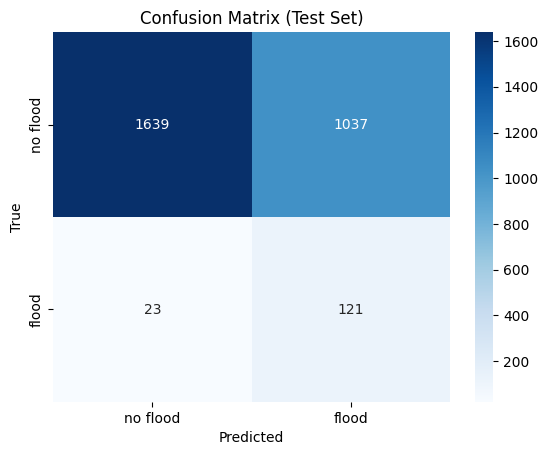

In [44]:
#confusion matrix of the test set
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.show()


#### Observation

On the test set (2020 to 2024) the tree finds 121 of the 144 floods (recall 0.84) and misses 23. Of the 2,676 months with no flood, 1,639 are correct and 1,037 get a false alarm, so the tree raises 1,158 warnings in total, which is 41% of all the test months. Only 121 of these warnings are real floods (precision 0.10, about 1 in 9.6), so for every flood found there are about 8.6 false alarms. Flood F1 is 0.19, and the accuracy is 62%, which is far below the 95% of always saying "no flood" (2,676 of 2,820), so accuracy is not a useful guide here.

The test recall (0.84) is higher than the cross-validation recall (0.664), but the test set has only 144 floods, so each flood found or missed moves the recall by 0.7 percentage points, and part of the difference may be luck. The precision (0.10) is lower than in cross-validation (0.181), partly because floods are rarer in the test years (5.1% of months against 8.9% in training). For comparison, a model that says "flood" for every month would have a recall of 1.0 but a precision of only 0.051; the tree's precision is about twice that, while still missing only 16% of the floods.


## 8. Comparison with Two Baselines

A model is only useful if it does better than simple rules that need no model. We compare it with two:

- **Persistence baseline:** predicts a flood next month whenever there is a flood this month (`flood_this_month`). It tests whether the model knows more than the current situation.
- **Calendar baseline:** gives every row the flood rate of its calendar month in the training years, so every March row gets the March rate, whatever the county or the rain. It tests whether the model knows more than the time of year. For a yes/no prediction it flags the months whose flood rate is above the overall training rate (8.9%).


In [45]:
#persistence baseline predictions on the test set
base_pred = test['flood_this_month']


In [46]:
#flood rate of each calendar month in the training years
month_rate = train.groupby('month')['flood_next_month'].mean()
month_rate.round(3)


month
1     0.016
2     0.090
3     0.183
4     0.185
5     0.054
6     0.020
7     0.046
8     0.044
9     0.069
10    0.131
11    0.134
12    0.102
Name: flood_next_month, dtype: float64

In [ ]:
#calendar baseline on the test set: the rate of the month, and yes/no when the rate is above the overall rate
calendar_prob = test['month'].map(month_rate)
calendar_pred = (calendar_prob > y_train.mean()).astype(int)

#### Observation

In the training years the months most often followed by a flood are March (18.3%) and April (18.5%), then November (13.4%), October (13.1%) and December (10.2%), while January (1.6%) and June (2.0%) are the lowest. The calendar baseline flags the six months above the overall rate of 8.9%: February, March, April, October, November and December. That is 1,410 of the 2,820 test rows.


### 8.1 The Three Methods Side by Side

PR-AUC (average precision) is added here. Like ROC-AUC it does not depend on a probability cut, but it focuses on the flood class: a method with no skill scores the flood share of the test set (0.051). A single tree gives only a few different probabilities (one per leaf), so many months are tied and the rankings behind ROC-AUC and PR-AUC are coarse.


In [48]:
#number of different flood probabilities the tree gives on the test set
pd.Series(y_prob).nunique()

23

In [49]:
#recall, precision, f1, roc-auc and pr-auc for the two baselines and the tree
comparison = pd.DataFrame({'method': ['Persistence baseline', 'Calendar baseline', 'Decision tree'],
                           'recall': [recall_score(y_test, base_pred), recall_score(y_test, calendar_pred), recall_score(y_test, y_pred)],
                           'precision': [precision_score(y_test, base_pred), precision_score(y_test, calendar_pred), precision_score(y_test, y_pred)],
                           'f1': [f1_score(y_test, base_pred), f1_score(y_test, calendar_pred), f1_score(y_test, y_pred)],
                           'roc-auc': [roc_auc_score(y_test, base_pred), roc_auc_score(y_test, calendar_prob), roc_auc_score(y_test, y_prob)],
                           'pr-auc': [average_precision_score(y_test, base_pred), average_precision_score(y_test, calendar_prob), average_precision_score(y_test, y_prob)]})
comparison.round(3)


,method,recall,precision,f1,roc-auc,pr-auc
0,Persistence baseline,0.472,0.472,0.472,0.722,0.250
1,Calendar baseline,0.847,0.087,0.157,0.762,0.141
2,Decision tree,0.840,0.104,0.186,0.718,0.112


#### Observation

The tree finds 121 of the 144 test floods (recall 0.840), almost the same as the calendar baseline (122 floods, recall 0.847), and it does this with fewer warnings (1,158 against 1,410), so its precision (0.104 against 0.087) and F1 (0.186 against 0.157) are higher. Persistence is the most precise method (precision 0.472, PR-AUC 0.250), but it finds only 68 of the 144 floods (recall 0.472), because a flood this month is a strong sign of a flood next month but many floods come without one.

On the ranking measures, which do not depend on the cut, the tree is weaker than both baselines: its ROC-AUC is 0.718 (calendar 0.762, persistence 0.722) and its PR-AUC is 0.112 (calendar 0.141, persistence 0.250). The PR-AUC is still about twice the value of a method with no skill (0.051). The tree gives only 23 different flood probabilities on the 2,820 test rows, about 123 rows per value, so many months are tied and the ranking is coarse. The tree is better than the calendar at choosing a smaller set of warnings, but it is not better at ordering the months by risk.


### 8.2 A Fair Recall Comparison

Recall depends on how many warnings a method raises: a method that flags more months will usually find more floods. To compare the tree and the calendar baseline fairly, we let the tree raise as many warnings as the calendar baseline, on the rows it thinks are most likely to flood. This is only a comparison, not a way of choosing the cut. Because the tree gives only a few different probabilities, rows with the same probability cannot be told apart, so the number of floods found is given as a range.


In [ ]:
#number of warnings raised by the calendar baseline and by the tree
print(calendar_pred.sum())
print(y_pred.sum())

1410
1158


In [ ]:
#ranking the test rows from the highest to the lowest flood probability
test_ranked = test.copy()
test_ranked['prob'] = y_prob
test_ranked = test_ranked.sort_values('prob', ascending=False)

In [52]:
#probability of the last warning if the tree raised as many warnings as the calendar baseline
cut_prob = test_ranked['prob'].iloc[calendar_pred.sum() - 1]
print(cut_prob)

0.3475154270867176


In [53]:
#warnings and floods found with a probability above the cut, and with a probability above or equal to the cut
above = test_ranked[test_ranked['prob'] > cut_prob]
print(len(above), above['flood_next_month'].sum())
equal_or_above = test_ranked[test_ranked['prob'] >= cut_prob]
print(len(equal_or_above), equal_or_above['flood_next_month'].sum())

1392 121
1508 121


#### Observation

The calendar baseline raises 1,410 warnings and the tree 1,158. For the tree to raise 1,410 warnings, its cut would have to fall from 0.5 to a probability of 0.348. The rows above 0.348 are 1,392 warnings and the rows above or equal to it are 1,508 (rows with exactly the same probability cannot be separated), and in both cases they contain 121 floods, the same 121 as at the 0.5 cut. The extra warnings add no flood: the tree finds 121 floods with 1,410 warnings, whichever way the tie is settled, against 122 for the calendar baseline (recall 0.840 against 0.847). So with the same number of warnings the tree is not better than the calendar baseline. Its higher precision in the table comes from raising 252 fewer warnings (1,158 against 1,410) for almost the same number of floods found. The two cannot be compared at 1,158 warnings, because the calendar baseline can only flag whole months. Because the tree has few different probabilities, a lower cut would add whole groups of rows at once, so choosing the cut would need cross-validation and would not change this result on the test set.


## 9. Looking Inside the Tree

A decision tree can be read like a flowchart: each box asks a yes/no question about one feature, and the rows go left (yes) or right (no) until they reach a leaf that gives the answer. In each box, `gini` shows how mixed the rows are (0 means only one class), `samples` is the number of training rows, `value` is the weight of the no-flood and flood rows (weighted, because of the balanced class weights) and `class` is the answer of the box.

### 9.1 The Top of the Tree


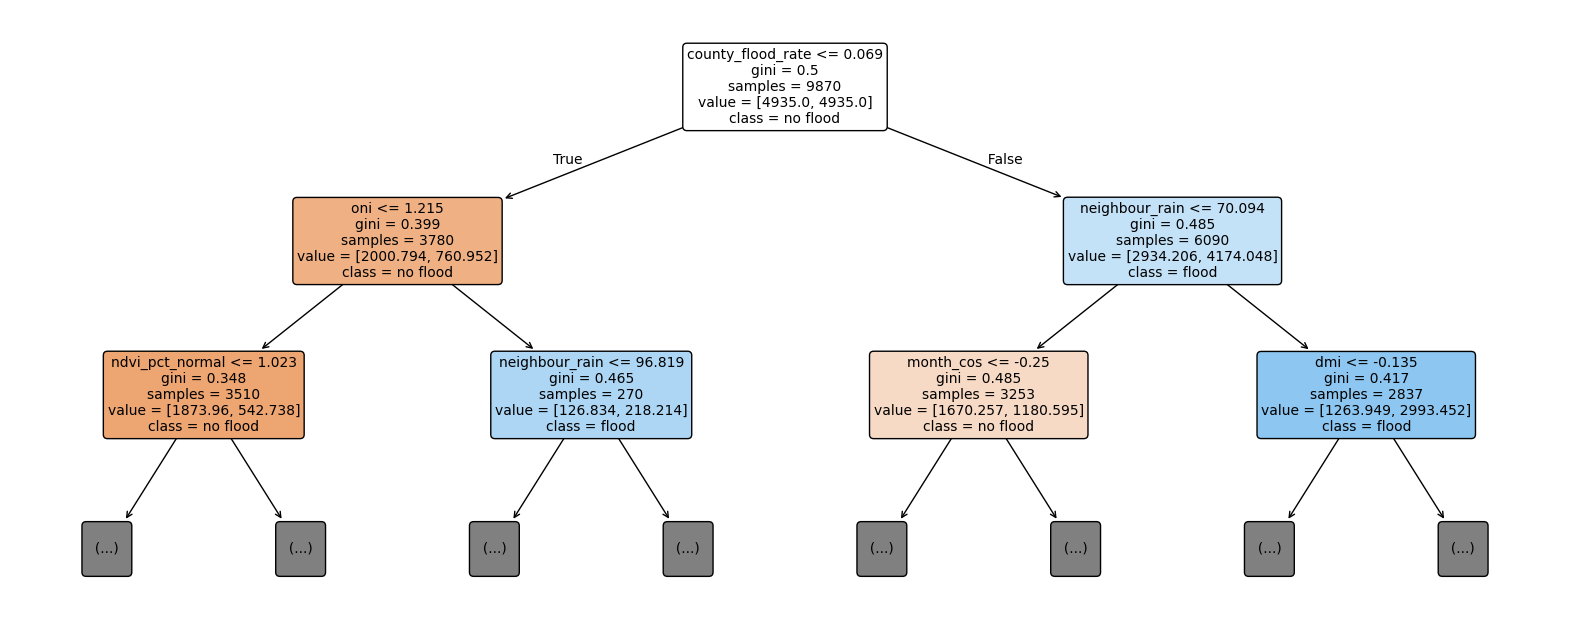

In [54]:
#the first two levels of the tree
plt.figure(figsize=(20, 8))
plot_tree(model, max_depth=2, feature_names=X_train.columns, class_names=['no flood', 'flood'], filled=True, rounded=True, fontsize=10)
plt.show()

### 9.2 The Full Tree


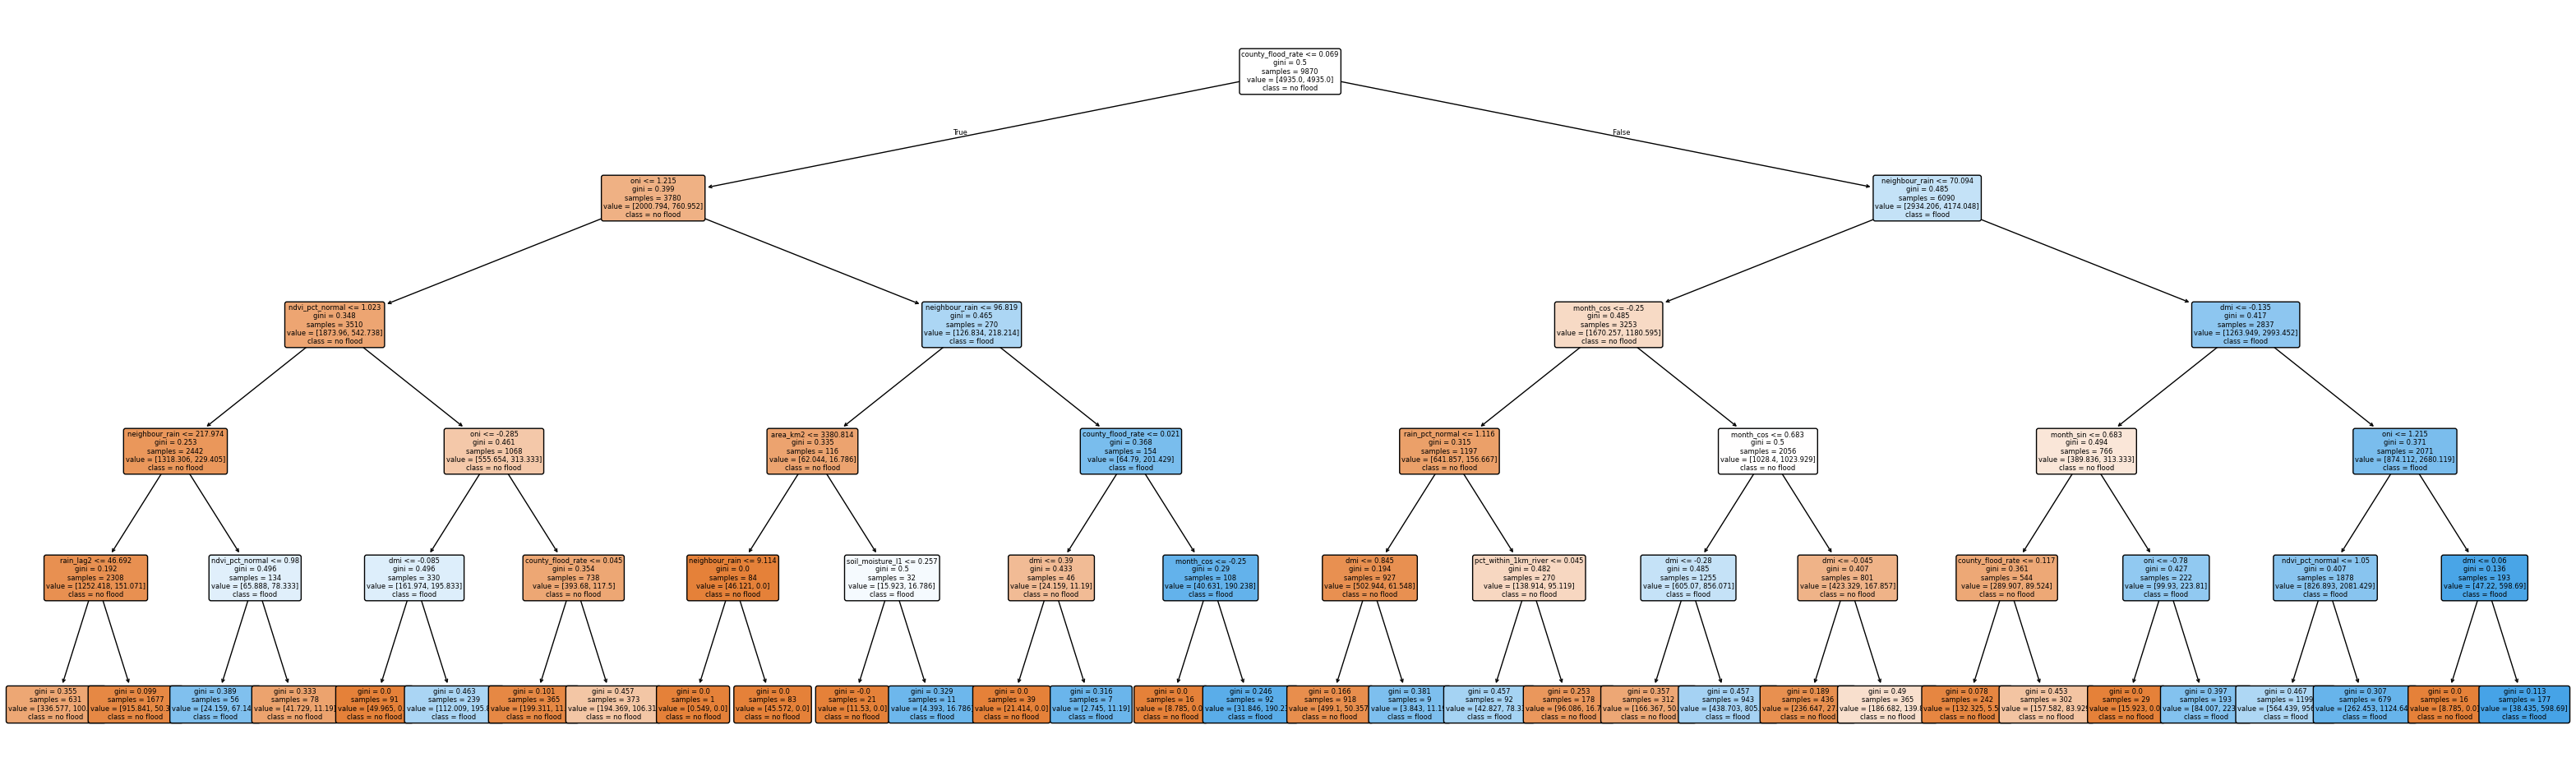

In [55]:
#the full tree (5 levels, 32 leaves)
plt.figure(figsize=(40, 12))
plot_tree(model, feature_names=X_train.columns, class_names=['no flood', 'flood'], filled=True, rounded=True, fontsize=6)
plt.show()


#### Observation

The first question of the tree is `county_flood_rate <= 0.069`. It splits the 9,870 training rows into 3,780 rows that answer yes and 6,090 that answer no. At the top both classes carry the same total weight (4,935 each), because of the balanced class weights. Dividing the flood weight in each side by the weight of one flood (4,935 / 882 = 5.6) gives about 136 floods in the 3,780 yes rows (3.6%) and about 746 in the 6,090 no rows (12.2%), so this one question already separates the counties that rarely flood from those that flood often. The next questions are `oni <= 1.215` on the yes side and `neighbour_rain <= 70.094` on the no side, and the third level uses `ndvi_pct_normal`, `neighbour_rain`, `month_cos` and `dmi`. Most of the yes side is coloured orange (class "no flood"), except the 270 rows with `oni` above 1.215, which the tree already calls "flood". On the no side, the 2,837 rows with `neighbour_rain` above 70.094 are mostly called "flood".

The full tree has 5 levels and 32 leaves. Most leaves are large, but a few hold very few rows (some only 1, 7, 9 or 11), so those leaves rest on very little evidence.


### 9.3 Feature Importance

The importance of a feature is how much it lowered the gini in all the questions that used it, scaled so that all 24 values add up to 1. It describes this tree only: features the tree never used have an importance of 0, and when two features carry similar information, the tree may use only one of them.


In [56]:
#importance of each feature, from the highest to the lowest
importance = pd.DataFrame({'feature': X_train.columns, 'importance': model.feature_importances_})
importance = importance.sort_values('importance', ascending=False)
importance.round(3)


,feature,importance
23,county_flood_rate,0.248
4,neighbour_rain,0.209
7,dmi,0.157
6,oni,0.116
9,month_cos,0.109
5,ndvi_pct_normal,0.066
8,month_sin,0.041
3,rain_pct_normal,0.016
19,pct_within_1km_river,0.016
2,rain_lag2,0.011


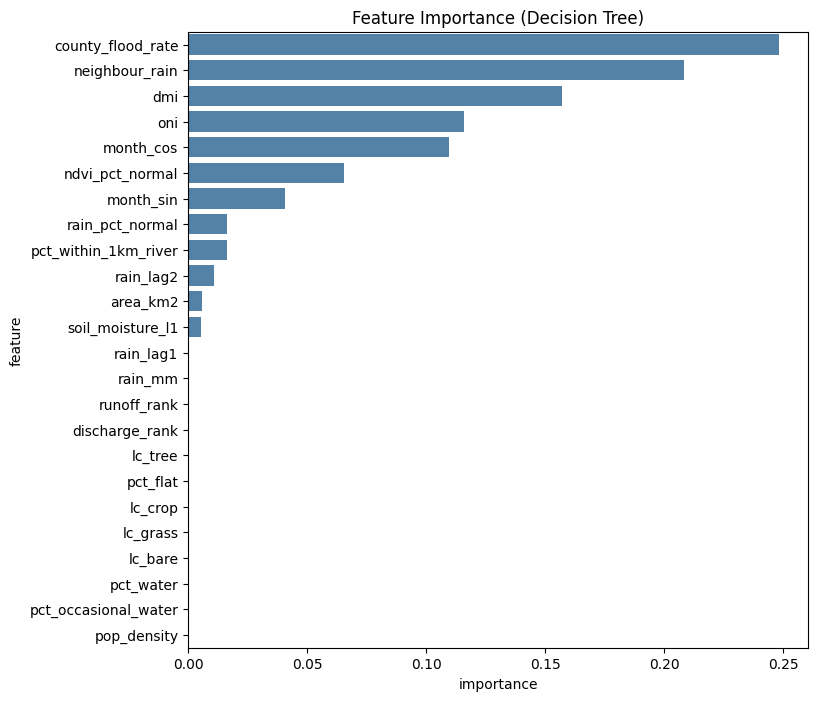

In [57]:
#bar chart of the feature importance
plt.figure(figsize=(8, 8))
sns.barplot(data=importance, x='importance', y='feature', color='steelblue')
plt.title('Feature Importance (Decision Tree)')
plt.show()


#### Observation

The tree uses 12 of the 24 features, and the other 12 have an importance that rounds to 0.000 (for example `rain_mm`, `rain_lag1`, the land cover columns and `pop_density`). The most important feature is `county_flood_rate` (0.248), followed by `neighbour_rain` (0.209), `dmi` (0.157), `oni` (0.116) and `month_cos` (0.109). These five together make up 0.839 of the total, and adding `ndvi_pct_normal` (0.066) and `month_sin` (0.041) brings it to 0.946. The two ocean-climate indices `oni` and `dmi` add up to 0.273, and the two month features to 0.150. The indices have the same value for every county in a month, so they help the tree decide which months are risky, while `county_flood_rate` helps it decide which counties are risky.

These importances describe this one tree only, trained on the training years. A feature with 0.000 is not necessarily useless: the tree may have used a similar feature instead, and a single tree can change its questions noticeably when the data change slightly. The top feature, `county_flood_rate`, is calculated from the training years, which is the reason the cross-validation scores are slightly optimistic (see the limits in Section 10).


## 10. Summary of the Decision Tree Model

- **Final model:** a decision tree with `max_depth=5`, `class_weight='balanced'`, `random_state=42` and the default probability cut of 0.5, trained on the 24 features (July 2002 to December 2019) to predict whether a county floods next month. It has 32 leaves.
- **How the model is judged:** recall for floods is the main measure, because a missed flood (predicting "no flood" when one happens) is the most dangerous mistake: a county is not warned and lives can be lost. A false alarm costs less, because a county prepares for a flood that does not come. But false alarms are not free: they waste stakeholders' money and staff time, and too many make people stop trusting the warnings. A model that says "flood" for every month would have a recall of 1.0 but a precision of only 0.051 on the test set, about 1 real flood in 20 warnings. F1 is the tie-breaker because it combines recall and precision and drops sharply when either is low (for example recall 0.95 with precision 0.06 gives an F1 of 0.11, while recall 0.75 with precision 0.20 gives 0.32). Accuracy is never used to judge the model, because always saying "no flood" already gets 91% on the training set and 95% on the test set. It is only used for the overfitting gap. ROC-AUC and PR-AUC use the predicted probabilities, so they judge how well the model ranks risky months independently of the 0.5 cut.
- **Overfitting:** the trees with no depth limit grew to 22 and 31 levels (668 and 840 leaves) and scored an accuracy of 1.0 on the training rows, but only 0.834 and 0.872 on years they had not seen (a gap of 0.166 and 0.128): they memorised the training years. Limiting the depth to 5 brings the gap down to 0.009 (0.691 on the training rows, 0.682 on unseen years).
- **Choosing the depth:** in cross-validation the mean flood recall was highest at depth 5 (0.664, standard deviation 0.047, precision 0.181, F1 0.279). It falls on both sides, to 0.607 at depth 3 and to 0.196 at depth 15. Depth 4 (0.628) was also within one standard deviation, and by the written rule its lower complexity would have won, but its fold recalls swing from 0.429 to 0.797 (standard deviation 0.138), so the more stable depth 5 was chosen. This was a decision beyond the rule and is stated in Section 6.
- **Class weights:** at depth 5 the balanced weights give a mean recall of 0.664 against only 0.044 without weights, because without weights almost no leaf has more than half floods and the tree says "no flood" nearly everywhere. The weights made little difference for the unlimited trees only because their leaves were almost all pure.
- **Cross-validation and test:** the cross-validation held out whole years, so each fold was tested on years the tree had not seen: recall 0.664 (folds from 0.617 to 0.742). On the test set (2020 to 2024) the recall is higher (0.840) and the precision lower (0.104 against 0.181). The test set has only 144 floods, so each flood found or missed moves the recall by 0.7 percentage points, and floods are rarer in the test years (5.1% of months against 8.9%), which lowers the precision.
- **Test results:** the tree finds 121 of the 144 floods (recall 0.840) and misses 23. Of the 2,676 months without a flood, 1,639 are correct and 1,037 get a false alarm. It raises 1,158 warnings (41% of the months), so about 1 warning in 9.6 is a real flood (precision 0.104, F1 0.186), with about 8.6 false alarms for every flood found.
- **Against the baselines:** the tree has almost the same recall as the calendar baseline (0.840 against 0.847) with fewer warnings (1,158 against 1,410), so a higher precision (0.104 against 0.087) and F1 (0.186 against 0.157). Persistence is the most precise (0.472) but finds only 68 of the 144 floods (recall 0.472). On the measures that rank months the tree is weaker: ROC-AUC 0.718 against 0.762 (calendar) and 0.722 (persistence), and PR-AUC 0.112 against 0.141 and 0.250, although its PR-AUC is about twice that of a method with no skill (0.051). With the same number of warnings as the calendar baseline (1,410), the tree finds 121 floods against 122, so it is not better than the time of year at ordering months by risk. The tree gives only 23 different probabilities, so many months are tied.
- **Important features:** the tree uses 12 of the 24 features. The most important are `county_flood_rate` (0.248), `neighbour_rain` (0.209), `dmi` (0.157), `oni` (0.116) and `month_cos` (0.109), and the first question of the tree is `county_flood_rate <= 0.069`. These describe this one tree and can change if the training data change slightly.
- **Limits:** the test set has only 144 floods, so its scores are uncertain. The probability cut was kept at 0.5 and not tuned. `county_flood_rate` is calculated from the training years, so it is slightly optimistic inside cross-validation. `GroupKFold` trains on years both before and after the held-out years, so it is not a pure forecast of the future. The recall changes noticeably from fold to fold (standard deviation 0.047 at depth 5), and a few leaves of the tree hold very few rows.
